# Course 11: On-Device AI
## Session 5: Pruning and sparsity

**Goal:** prune an MLP by weight magnitude (one-shot and iterative) and a CNN by whole channels, measure what each sparsity does to accuracy, size and single-thread latency, find where sparse matrix–vector products beat dense ones, and test a lottery-ticket claim with a fair control.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Setup and a dense MLP
**Pruning** removes weights. **Sparsity** is the fraction removed: 90% sparse means 10% of the weights are left. We start with an MLP (64 → 256 → 256 → 10, 84,480 weights) on the 8 × 8 digits (1,257 training and 540 test images), trained densely. Pruned weights are kept at zero during later training by multiplying the weights by a 0/1 **mask** after every optimizer step.

In [1]:
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[_v] = "1"                     # one BLAS thread for NumPy; set before NumPy is imported
import time, copy, warnings
import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

torch.set_num_threads(1)
torch.manual_seed(0); np.random.seed(0)
warnings.filterwarnings("ignore", message="Sparse CSR tensor support is in beta")
t_start = time.time()

digits = load_digits()
perm = np.random.default_rng(0).permutation(len(digits.target))
tr, te = perm[:1257], perm[1257:]
X64 = torch.tensor(digits.data / 16.0, dtype=torch.float32)
y_all = torch.tensor(digits.target)
Xtr, ytr, Xte, yte = X64[tr], y_all[tr], X64[te], y_all[te]

def make_mlp(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 10))

def weights(model):
    return [m.weight for m in model.modules() if isinstance(m, (nn.Linear, nn.Conv2d))]

def train(model, epochs, X, y, lr=1e-3, masks=None, seed=0, onecycle=False):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * ((len(X) + 63) // 64)) if onecycle else None
    model.train()
    for _ in range(epochs):
        order = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), 64):
            b = order[i:i + 64]
            loss = F.cross_entropy(model(X[b]), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            if sched is not None:
                sched.step()
            if masks is not None:
                with torch.no_grad():
                    for w, m in zip(weights(model), masks):
                        w.mul_(m)
    return model.eval()

def accuracy(model, X=Xte, y=yte):
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def apply(model, masks):
    with torch.no_grad():
        for w, m in zip(weights(model), masks):
            w.mul_(m)
    return model

def magnitude_masks(model, sparsity):          # global: one threshold for all layers
    flat = torch.cat([w.detach().abs().flatten() for w in weights(model)])
    k = int(sparsity * flat.numel())
    thr = flat.kthvalue(k).values if k > 0 else torch.tensor(-1.0)
    return [(w.detach().abs() > thr).float() for w in weights(model)]

dense = train(make_mlp(0), 30, Xtr, ytr)
n_weights = sum(w.numel() for w in weights(dense))
print(f"dense MLP: {n_weights:,d} weights, test accuracy {accuracy(dense):.3f}")

dense MLP: 84,480 weights, test accuracy 0.983


### 2. Magnitude pruning: one-shot against iterative
**Magnitude pruning** (Han et al. 2015) removes the weights with the smallest absolute values, then fine-tunes the rest so the network can adapt. We compare, at sparsities from 50% to 98%, with the same fine-tuning budget of 12 epochs:

* **one-shot, no fine-tuning**: prune once and test;
* **one-shot + fine-tuning**: prune once, then 12 epochs;
* **iterative**: four rounds that remove a growing share of the weights ($1 - (1-s)^{r/4}$ after round $r$), each followed by 3 epochs.

We also try **2:4 sparsity** (Mishra et al. 2021): in every group of 4 consecutive weights in a row, keep the 2 largest. It is always exactly 50% sparse, in a regular pattern that some GPUs can skip in hardware.

sparsity | one-shot, no fine-tuning |     one-shot + 12 epochs |  iterative, 4 x 3 epochs
    0.50 |                    0.974 |                    0.980 |                    0.980
    0.70 |                    0.967 |                    0.981 |                    0.987
    0.80 |                    0.970 |                    0.981 |                    0.987
    0.90 |                    0.804 |                    0.980 |                    0.980
    0.95 |                    0.339 |                    0.954 |                    0.959
    0.98 |                    0.093 |                    0.481 |                    0.787


unstructured 50%: accuracy without fine-tuning 0.974, after 12 epochs 0.980


2:4 (50%)       : accuracy without fine-tuning 0.965, after 12 epochs 0.981


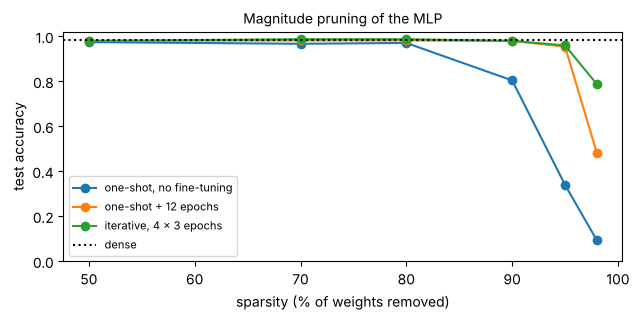

In [2]:
sparsities = [0.5, 0.7, 0.8, 0.9, 0.95, 0.98]
res = {"one-shot, no fine-tuning": [], "one-shot + 12 epochs": [], "iterative, 4 x 3 epochs": []}
for s in sparsities:
    m = apply(copy.deepcopy(dense), magnitude_masks(dense, s))
    res["one-shot, no fine-tuning"].append(accuracy(m))
    masks = magnitude_masks(dense, s)
    res["one-shot + 12 epochs"].append(accuracy(train(apply(copy.deepcopy(dense), masks), 12, Xtr, ytr, masks=masks)))
    m = copy.deepcopy(dense)
    for r in range(1, 5):
        masks = magnitude_masks(m, 1 - (1 - s) ** (r / 4))
        m = train(apply(m, masks), 3, Xtr, ytr, masks=masks)
    res["iterative, 4 x 3 epochs"].append(accuracy(m))
print(f"{'sparsity':>8s} | " + " | ".join(f"{k:>24s}" for k in res))
for i, s in enumerate(sparsities):
    print(f"{s:8.2f} | " + " | ".join(f"{res[k][i]:24.3f}" for k in res))

def nm_masks(model, n=2, m=4):
    out = []
    for w in weights(model):
        a = w.detach().abs().reshape(w.shape[0], -1, m)
        keep = a.argsort(dim=2, descending=True)[..., :n]
        out.append(torch.zeros_like(a).scatter_(2, keep, 1.0).reshape(w.shape))
    return out
for name, masks in [("unstructured 50%", magnitude_masks(dense, 0.5)), ("2:4 (50%)", nm_masks(dense))]:
    m = train(apply(copy.deepcopy(dense), masks), 12, Xtr, ytr, masks=masks)
    print(f"{name:16s}: accuracy without fine-tuning {accuracy(apply(copy.deepcopy(dense), masks)):.3f}, after 12 epochs {accuracy(m):.3f}")

plt.figure(figsize=(6.5, 3.3))
for k, v in res.items():
    plt.plot([100 * s for s in sparsities], v, "o-", label=k)
plt.axhline(accuracy(dense), color="k", ls=":", label="dense")
plt.xlabel("sparsity (% of weights removed)"); plt.ylabel("test accuracy"); plt.ylim(0, 1.02)
plt.title("Magnitude pruning of the MLP", fontsize=10); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 3. Does unstructured sparsity make a matrix–vector product faster?
A pruned matrix only saves time if the kernel skips the zeros. The usual sparse format is **CSR** (compressed sparse row): the nonzero values (4 bytes each in float32), their column indices (4 bytes each) and one pointer per row. So CSR needs about 8 bytes per *kept* weight against 4 bytes per weight for a dense matrix, and its memory accesses are irregular. We time a 4,096 × 4,096 matrix–vector product (the shape of LLM decoding) with randomly placed zeros: dense PyTorch, SciPy CSR and PyTorch CSR, on one thread, timed in turn for each sparsity. Other programs on this shared machine change the absolute times during the run (the dense product is the same in every row), so compare the speed-up within each row; the plot shows it against the ideal $1/(1 - \text{sparsity})$.

sparsity | dense (ms) | SciPy CSR (ms) | PyTorch CSR (ms) | CSR MB | dense MB | best speed-up over dense


    0.50 |      4.910 |          9.133 |           16.474 |   67.1 |     67.1 | 0.54


    0.70 |      5.081 |          5.855 |            9.794 |   40.3 |     67.1 | 0.87


    0.80 |      4.709 |          3.711 |            5.917 |   26.8 |     67.1 | 1.27


    0.90 |      3.236 |          1.366 |            1.675 |   13.4 |     67.1 | 2.37


    0.95 |      2.867 |          0.609 |            0.814 |    6.7 |     67.1 | 4.71


    0.98 |      2.548 |          0.251 |            0.338 |    2.7 |     67.1 | 10.14


    0.99 |      2.547 |          0.190 |            0.200 |    1.4 |     67.1 | 13.40


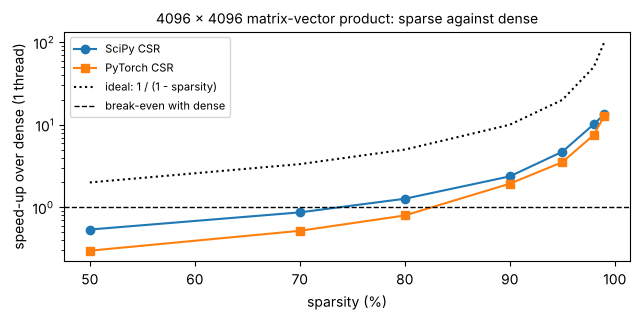

In [3]:
def compare_ms(fns, reps=30, warmup=5):
    for f in fns.values():
        for _ in range(warmup):
            f()
    ts = {k: [] for k in fns}
    for _ in range(reps):
        for k, f in fns.items():
            t0 = time.perf_counter(); f(); ts[k].append(time.perf_counter() - t0)
    return {k: float(np.median(v)) * 1e3 for k, v in ts.items()}

n = 4096
rng = np.random.default_rng(0)
Wd = rng.standard_normal((n, n)).astype(np.float32)
xv = rng.standard_normal(n).astype(np.float32)
Wt, xt = torch.from_numpy(Wd), torch.from_numpy(xv)
rows = []
print(f"{'sparsity':>8s} | dense (ms) | SciPy CSR (ms) | PyTorch CSR (ms) | CSR MB | dense MB | best speed-up over dense")
with torch.inference_mode():
    for s in [0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99]:
        Ms = Wd * (rng.random((n, n), dtype=np.float32) >= s)
        A = sp.csr_matrix(Ms); At = torch.from_numpy(Ms).to_sparse_csr()
        t = compare_ms({"dense": lambda: Wt @ xt, "scipy": lambda: A @ xv, "torch": lambda: At @ xt})
        mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6
        rows.append((s, t["dense"], t["scipy"], t["torch"]))
        print(f"{s:8.2f} | {t['dense']:10.3f} | {t['scipy']:14.3f} | {t['torch']:16.3f} | {mb:6.1f} | {Wd.nbytes / 1e6:8.1f} | "
              f"{t['dense'] / min(t['scipy'], t['torch']):.2f}")
        del Ms, A, At
r = np.array(rows)
plt.figure(figsize=(6.5, 3.3))
plt.semilogy(100 * r[:, 0], r[:, 1] / r[:, 2], "o-", label="SciPy CSR")
plt.semilogy(100 * r[:, 0], r[:, 1] / r[:, 3], "s-", label="PyTorch CSR")
plt.semilogy(100 * r[:, 0], 1 / (1 - r[:, 0]), "k:", label="ideal: 1 / (1 - sparsity)")
plt.axhline(1, color="k", ls="--", lw=1, label="break-even with dense")
plt.xlabel("sparsity (%)"); plt.ylabel("speed-up over dense (1 thread)")
plt.title("4096 x 4096 matrix-vector product: sparse against dense", fontsize=10)
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 4. Structured pruning: removing whole channels
**Structured pruning** removes whole filters (output channels), so the result is simply a smaller dense network that every runtime runs fast. Li et al. (2017) rank each convolution's filters by the **L1 norm** of their weights and remove the smallest; the next layer loses the matching input channels. Our CNN works on the digits upsampled to 16 × 16: three 3 × 3 convolutions with 32, 64 and 64 channels (the third with stride 2), each followed by batch normalization and ReLU, then global average pooling and a linear layer. We keep the half of the filters with the largest L1 norms in every convolution. Removing channels changes the statistics that batch normalization saw in training, so we first re-estimate them on the training images (no weights change), then fine-tune for 5 epochs. A fair baseline (Blalock et al. 2020) is the same small architecture trained from scratch for 20 epochs, as many as the original 15 plus the 5 of fine-tuning.

In [4]:
X16 = torch.tensor(np.kron(digits.images / 16.0, np.ones((1, 2, 2))), dtype=torch.float32).unsqueeze(1)
Xtr16, Xte16 = X16[tr], X16[te]

class CNN(nn.Module):
    def __init__(self, c=(32, 64, 64)):
        super().__init__()
        self.convs = nn.ModuleList([nn.Conv2d(1, c[0], 3, padding=1, bias=False),
                                    nn.Conv2d(c[0], c[1], 3, padding=1, bias=False),
                                    nn.Conv2d(c[1], c[2], 3, stride=2, padding=1, bias=False)])
        self.bns = nn.ModuleList([nn.BatchNorm2d(k) for k in c])
        self.fc = nn.Linear(c[2], 10)
    def forward(self, x):
        for conv, bn in zip(self.convs, self.bns):
            x = F.relu(bn(conv(x)))
        return self.fc(x.mean(dim=(2, 3)))

def cnn_macs(c):
    return 16 * 16 * c[0] * 9 + 16 * 16 * c[1] * c[0] * 9 + 8 * 8 * c[2] * c[1] * 9 + c[2] * 10

def prune_channels(model, keep=0.5):
    idx = [conv.weight.detach().abs().sum(dim=(1, 2, 3)).argsort(descending=True)[:int(keep * conv.out_channels)].sort().values
           for conv in model.convs]                                   # filters with the largest L1 norms
    small = CNN(tuple(len(i) for i in idx))
    with torch.no_grad():
        prev = torch.arange(1)
        for new, old, nbn, obn, i in zip(small.convs, model.convs, small.bns, model.bns, idx):
            new.weight.copy_(old.weight[i][:, prev])                 # kept filters, kept input channels
            for name in ["weight", "bias", "running_mean", "running_var"]:
                getattr(nbn, name).copy_(getattr(obn, name)[i])
            prev = i
        small.fc.weight.copy_(model.fc.weight[:, prev]); small.fc.bias.copy_(model.fc.bias)
    return small.eval()

def recalibrate_bn(model, X):                  # re-estimate batch-norm statistics; no weights change
    for bn in model.bns:
        bn.reset_running_stats(); bn.momentum = None                 # momentum None: a plain average over batches
    model.train()
    with torch.no_grad():
        for i in range(0, len(X), 64):
            model(X[i:i + 64])
    for bn in model.bns:
        bn.momentum = 0.1
    return model.eval()

torch.manual_seed(0)
big = train(CNN(), 15, Xtr16, ytr, lr=3e-3, onecycle=True)
small = prune_channels(big, 0.5)
acc_pruned = accuracy(small, Xte16)
acc_recal = accuracy(recalibrate_bn(small, Xtr16), Xte16)
small = train(small, 5, Xtr16, ytr, lr=1e-3)
torch.manual_seed(1)
scratch = train(CNN((16, 32, 32)), 20, Xtr16, ytr, lr=3e-3, onecycle=True)
n_big, n_small = sum(p.numel() for p in big.parameters()), sum(p.numel() for p in small.parameters())
print(f"{'original (32, 64, 64)':36s}: accuracy {accuracy(big, Xte16):.3f}, {n_big:6,d} parameters, {cnn_macs((32, 64, 64)):9,d} MACs")
for name, a in [("pruned to (16, 32, 32), no training", acc_pruned), ("pruned, batch norm re-estimated", acc_recal),
                ("pruned + 5 epochs of fine-tuning", accuracy(small, Xte16)), ("small, from scratch (20 epochs)", accuracy(scratch, Xte16))]:
    print(f"{name:36s}: accuracy {a:.3f}, {n_small:6,d} parameters, {cnn_macs((16, 32, 32)):9,d} MACs")
with torch.inference_mode():
    for B in [1, 64]:
        xb = Xte16[:B]
        t = compare_ms({"original": lambda: big(xb), "pruned": lambda: small(xb)}, reps=100 if B == 1 else 30)
        print(f"batch {B:2d}: original {t['original']:.3f} ms, pruned {t['pruned']:.3f} ms, "
              f"speed-up {t['original'] / t['pruned']:.2f} (MAC ratio {cnn_macs((32, 64, 64)) / cnn_macs((16, 32, 32)):.2f})")

original (32, 64, 64)               : accuracy 0.993, 56,554 parameters, 7,152,256 MACs
pruned to (16, 32, 32), no training : accuracy 0.098, 14,458 parameters, 1,806,656 MACs
pruned, batch norm re-estimated     : accuracy 0.394, 14,458 parameters, 1,806,656 MACs
pruned + 5 epochs of fine-tuning    : accuracy 0.972, 14,458 parameters, 1,806,656 MACs
small, from scratch (20 epochs)     : accuracy 0.983, 14,458 parameters, 1,806,656 MACs
batch  1: original 0.314 ms, pruned 0.168 ms, speed-up 1.87 (MAC ratio 3.96)


batch 64: original 12.247 ms, pruned 3.754 ms, speed-up 3.26 (MAC ratio 3.96)


### 5. A lottery-ticket test, with its control
The **lottery ticket hypothesis** (Frankle & Carbin 2019) says that a dense network contains a sparse subnetwork that, trained alone *from its original initial weights*, reaches the dense network's accuracy. The test: train densely from initial weights $\theta_0$, prune to 95% sparsity by magnitude, **rewind** the surviving weights to their values in $\theta_0$ and retrain with the mask. The **control** keeps the same mask but draws new random initial weights. If the ticket clearly beats the control, the initial values matter, not only the mask. We use one-shot pruning and three seeds; Course 3 session 3 runs the full iterative version.

In [5]:
lt = []
for seed in [0, 1, 2]:
    net0 = make_mlp(seed)
    theta0 = copy.deepcopy(net0.state_dict())
    trained = train(net0, 30, Xtr, ytr, seed=seed)
    masks = magnitude_masks(trained, 0.95)
    ticket = make_mlp(seed); ticket.load_state_dict(theta0)                 # rewind to theta_0
    ticket = train(apply(ticket, masks), 30, Xtr, ytr, masks=masks, seed=seed)
    control = make_mlp(seed + 100)                                           # same mask, new random weights
    control = train(apply(control, masks), 30, Xtr, ytr, masks=masks, seed=seed)
    lt.append((accuracy(trained), accuracy(ticket), accuracy(control)))
    print(f"seed {seed}: dense {lt[-1][0]:.3f}, ticket (rewound) {lt[-1][1]:.3f}, control (re-initialized) {lt[-1][2]:.3f}")
lt = np.array(lt)
print(f"mean over 3 seeds: dense {lt[:, 0].mean():.3f}, ticket {lt[:, 1].mean():.3f}, control {lt[:, 2].mean():.3f}; "
      f"ticket minus control per seed: {np.round(lt[:, 1] - lt[:, 2], 3)}")

seed 0: dense 0.983, ticket (rewound) 0.956, control (re-initialized) 0.948


seed 1: dense 0.980, ticket (rewound) 0.963, control (re-initialized) 0.935


seed 2: dense 0.976, ticket (rewound) 0.965, control (re-initialized) 0.944
mean over 3 seeds: dense 0.980, ticket 0.961, control 0.943; ticket minus control per seed: [0.007 0.028 0.02 ]


### 6. Pruning plus quantization
Deep Compression (Han, Mao & Dally 2016) combined pruning, quantization and Huffman coding. A small version: take the 90%-sparse MLP from section 2 (one-shot + fine-tuning), store it in CSR, and then also quantize the kept weights to int8 with one scale per row. Because no layer here has more than 256 inputs, each column index fits in one byte.

In [6]:
masks90 = magnitude_masks(dense, 0.9)
mlp90 = train(apply(copy.deepcopy(dense), masks90), 12, Xtr, ytr, masks=masks90)
Ws = [w.detach().numpy() for w in weights(mlp90)]
n_bias = sum(m.bias.numel() for m in mlp90.modules() if isinstance(m, nn.Linear))
nnz = sum(int((w != 0).sum()) for w in Ws); rows_total = sum(w.shape[0] for w in Ws)
sizes = {"dense float32": 4 * n_weights + 4 * n_bias,
         "CSR, float32 values, int32 indices": 8 * nnz + 4 * (rows_total + len(Ws)) + 4 * n_bias,
         "CSR, int8 values, uint8 indices, row scales": 2 * nnz + 4 * (rows_total + len(Ws)) + 4 * rows_total + 4 * n_bias}
mq = copy.deepcopy(mlp90)
with torch.no_grad():
    for w in weights(mq):
        s = (w.abs().amax(dim=1, keepdim=True) / 127).clamp_min(1e-12)   # a fully pruned row has no range
        w.copy_(torch.round(w / s).clamp(-127, 127) * s)
print(f"90% sparse MLP: {nnz:,d} weights kept; accuracy {accuracy(mlp90):.3f} (float), {accuracy(mq):.3f} (int8 values)")
for k, v in sizes.items():
    print(f"  {k:45s}: {v:7,d} bytes ({sizes['dense float32'] / v:4.1f} times smaller than dense float32)")

90% sparse MLP: 8,448 weights kept; accuracy 0.980 (float), 0.980 (int8 values)
  dense float32                                : 340,008 bytes ( 1.0 times smaller than dense float32)
  CSR, float32 values, int32 indices           :  71,772 bytes ( 4.7 times smaller than dense float32)
  CSR, int8 values, uint8 indices, row scales  :  23,172 bytes (14.7 times smaller than dense float32)


### 7. Exercises

In [7]:
# TODO: layer-wise against global pruning. Write layerwise_masks(model, sparsity) that removes the same fraction of
# weights from EACH layer (its own threshold per layer), and compare it with magnitude_masks (one global threshold) at
# 90% and 95%, one-shot + 12 epochs. Print how many weights each method leaves in the last layer (640 weights).
def layerwise_masks(model, sparsity):
    return None          # replace with a list of masks

r = layerwise_masks(dense, 0.9)
print("not done yet" if r is None else [int(m.sum()) for m in r])

not done yet


In [8]:
# TODO: how far can channel pruning go? Repeat section 4 keeping 25% of the filters (8, 16, 16 channels) instead of
# 50%. Report accuracy before and after fine-tuning, the from-scratch baseline, MACs and the batch-1 speed-up.
def channel_prune_25():
    return None          # replace with a dict of results

r = channel_prune_25()
print("not done yet" if r is None else r)
print(f"runtime so far {time.time() - t_start:.0f} s")

not done yet
runtime so far 48 s


### What to notice
(Written from the saved run. Accuracies and byte counts are the same on every run. Timings vary: in the sparse table, the dense product itself went from about 5 ms to 2.5 ms during the run because other programs shared the machine, so read the speed-ups within each row. Across our test runs the break-even sparsity and the 90% speed-up stayed close to the values below.)

1. **Pruning needs fine-tuning, and extreme sparsity needs iteration.** The dense MLP (84,480 weights) scored 0.983. Pruned in one shot with no fine-tuning, it held 0.970 at 80% sparsity but fell to 0.804 at 90%, 0.339 at 95% and 0.093 at 98%. With 12 epochs of fine-tuning, one-shot pruning kept 0.980–0.981 up to 90%, then 0.954 at 95% and 0.481 at 98%. Iterative pruning with the same 12 epochs kept 0.980–0.987 up to 90%, 0.959 at 95% and 0.787 at 98%: the gain from iterating appears only at the highest sparsity.
2. **2:4 sparsity was as good as unstructured 50% after fine-tuning:** 0.981 against 0.980 (before fine-tuning, 0.965 against 0.974).
3. **90% sparse was not 10 times faster.** At 50% sparsity the CSR matrix took as many bytes as the dense one (67.1 MB) and SciPy's product was slower (speed-up 0.54). The break-even point lay between 70% and 80% (0.87 and 1.27). At 90% the speed-up was 2.37, at 95% 4.71, at 98% 10.14 and at 99% 13.40, always far below the ideal $1/(1 - \text{sparsity})$. PyTorch's CSR product was slower than SciPy's at every sparsity.
4. **Removing whole channels gave real speed, but not more accuracy than training small.** Keeping half the filters cut the parameters from 56,554 to 14,458 and the MACs 3.96 times. Right after pruning, accuracy was 0.098; re-estimating the batch-norm statistics gave 0.394, and 5 epochs of fine-tuning gave 0.972 (the original scored 0.993). The pruned network ran 1.87 times faster at batch 1 and 3.26 times faster at batch 64, in plain PyTorch, because it is simply a smaller dense network. **Against the plan's expectation,** the same small architecture trained from scratch for 20 epochs scored 0.983, better than pruning plus fine-tuning. This is exactly why a fair baseline matters (Blalock et al. 2020); with one seed each, the gap of 0.011 (about 6 test images) is small.
5. **The lottery ticket beat its control, weakly.** At 95% sparsity, the rewound ticket averaged 0.961 and the re-initialized control 0.943 over three seeds; the ticket was ahead in every seed (by 0.007, 0.028 and 0.020), and neither matched the dense network (0.980). This is modest support at this small scale with one-shot pruning; Course 3 session 3 finds tickets by iterative pruning.
6. **Pruning and quantization multiply.** The 90%-sparse MLP kept 0.980 in float and 0.980 with int8 values. Stored in CSR with float32 values and int32 indices it took 71,772 bytes (4.7 times smaller than dense float32); with int8 values and one-byte indices, 23,172 bytes (14.7 times smaller). In float32 CSR the indices cost as much as the values.
7. **What transfers to a phone.** Accuracy and byte counts transfer exactly. The speed of unstructured sparsity does not: it needs a runtime with sparse kernels for that layer and very high sparsity. Channel pruning gives a smaller dense network, which every runtime runs faster.